# StomataQuant — headless stomata detection and measurement on a StomataQuant test image

**Paper:** Liu, M.-L., Ren, Z.-R., Wei, J., Zhang, H., Li, Y.-K., Wang, G.-Y., Xie, P., & Wang, Y. (2026).
*Integrating automated detection and segmentation for quantitative analysis of stomata and pavement cells using StomataQuant.*
**Journal of Plant Ecology**, rtag063. [doi:10.1093/jpe/rtag063](https://doi.org/10.1093/jpe/rtag063)

**Tool:** [StomataQuant](https://github.com/Milo-L/StomataQuant) (AGPL-3.0) — a PyQt5 GUI over Ultralytics YOLO11
detection/segmentation models with automatic geometric measurements. The released detection weights are hosted by the
authors on the PKU cloud disk (pickup code published in the README) and the paper's supplementary datasets are on
Zenodo ([record 18934358](https://zenodo.org/records/18934358), CC-covered supplementary data of the same paper).

**Scope of this notebook (partial demonstration):** reproduce the GUI workflow
*"Open image → choose model → Run AI → automatic measurements"* **headlessly** for the **stomata detection** task on
one independent test image from the paper's S2 test set, using the authors' exact inference defaults from the pinned
source (`InferenceThread.py`: conf=0.5, iou=0.7, imgsz=1024, max_det=500, retina_masks=True), and the tool's
measurement step (minimum enclosing rectangle via `cv2.minAreaRect`, as in `geometry.py`). Predicted stomata counts
are compared with the released ground-truth labels. This is **AI-assisted headless port of the GUI steps**; the
authors did not provide this notebook. One small example does not verify the paper's dataset-level concordance results.

**実行内容(概要):** StomataQuant の GUI ワークフロー(画像を開く→モデル選択→AI実行→自動計測)を、
作者が公開した検出モデル重みと S2 テスト画像を使ってヘッドレス(Python のみ)で再現し、
推定した気孔数を正解ラベルと比較します。単一サンプルの部分的なデモであり、論文のデータセット全体の
一致度検証ではありません。

**Execution status / 実行状態:** fully executed on a fresh Colab CPU runtime (see validation record at the end).
The GPU branch is code-verified only (device mapping mirrors `InferenceThread.py`); this notebook was validated on CPU.

**License note:** Author code excerpts follow AGPL-3.0 (Milo-L/StomataQuant). Model weights are downloaded from the
authors' own public share; all downloaded bytes stay inside this VM's `/content`.

## 1. Runtime selection — ランタイム選択

**Recommended runtime: CPU** (Runtime → Change runtime type → CPU). The demonstration runs a 5–40 MB YOLO11
detection weight on **one** image; on CPU this takes seconds and no GPU is needed. If a GPU runtime is allocated
instead, the notebook automatically uses it (`device="0"`, mirroring the GUI's Inference Setting → device mapping in
`InferenceThread.py`). Expected total time on CPU: ~3–6 minutes (setup ≈1 min, downloads ≈25 MB, inference seconds).
**推奨ランタイムは CPU です。GPU を割り当てた場合は自動で GPU 推論に切り替わります。**

Select **Runtime → Run all** to execute everything. All downloads happen inside this notebook; nothing is fetched
outside the VM.

## 2. Environment setup — 環境セットアップ

**Cell purpose:** install Ultralytics YOLO (the framework the author's `inference_worker.py` uses) and print the
versions of everything this demo depends on. Colab already provides `torch`, `opencv`, `numpy`, `matplotlib`, and
`pillow`; only `ultralytics` needs installation.

**このセルの目的:** 推論に必要な Ultralytics をインストールし、バージョンを確認します。

In [ ]:
import time
t_setup0 = time.time()
%pip install -q ultralytics
import sys, torch, cv2, numpy as np, matplotlib, PIL
import ultralytics
print("python:", sys.version.split()[0])
print("torch:", torch.__version__, "| cuda available:", torch.cuda.is_available())
print("ultralytics:", ultralytics.__version__, "| opencv:", cv2.__version__, "| numpy:", np.__version__)
print(f"setup time: {time.time()-t_setup0:.1f} s")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.


python: 3.13.18
torch: 2.11.0+cpu | cuda available: False
ultralytics: 8.4.191 | opencv: 5.0.0 | numpy: 2.1.3
setup time: 10.5 s


## 3. Model weights — 検出モデル重みの取得

**Cell purpose:** authenticate to the authors' PKU cloud-disk share with the **public pickup code** printed in the
StomataQuant README ("Model Weights" section). The share gate is a plain HTML form (`POST /link`); submitting the code
sets a `link_token` cookie that authorizes the AnyShare REST API. No credentials beyond the public code are used.

**このセルの目的:** README に公開されているピックアップコードで著者の PKU クラウドディスク共有を認証します
(秘密情報は不要です)。

In [ ]:
import requests, re
SHARE = "https://disk.pku.edu.cn/link/AA705A6764E6CE4081BBBAFA4F58E2707F"  # "Stomata detection" share (README)
PICKUP_CODE = "mmxr"  # public pickup code published in the StomataQuant README

s = requests.Session()
page = s.get(SHARE, timeout=60)
page.raise_for_status()
fields = dict(re.findall(r'<input type="hidden" name="([^"]+)" value="([^"]*)"', page.text))
link_id = fields["id"]
post = dict(fields); post["password"] = PICKUP_CODE
post.pop("logo", None); post.pop("favicon", None)  # strip big inline images from the form
resp = s.post("https://disk.pku.edu.cn/link", data=post, timeout=60, allow_redirects=True)
resp.raise_for_status()
link_token = s.cookies.get("link_token:" + link_id)
assert link_token, "link_token cookie missing — share authentication failed"
API_HEADERS = {"Authorization": "Bearer " + link_token}
API = "https://disk.pku.edu.cn/api"
print("share authenticated:", resp.url[:80], "| token bytes:", len(link_token))

share authenticated: https://disk.pku.edu.cn/anyshare/link/AA705A6764E6CE4081BBBAFA4F58E2707F?type=an | token bytes: 94


**Cell purpose:** resolve the shared folder's internal id (`entry-item`), list its files
(`dir/list`), and locate the released detection weight `stomata_detect_model_s_best.pt` (the *small* YOLO11 variant;
larger n/m/l/xl variants are also published — the README notes larger models are slower on CPU, and "s" keeps this demo
fast while matching the released weights). Asserts the exact name and byte size observed in the authors' folder.

**このセルの目的:** 共有フォルダ内の重み一覧を取得し、small 版の検出モデル重みを特定します。

In [ ]:
entry = s.get(f"{API}/efast/v1/entry-item", headers=API_HEADERS, timeout=30).json()[0]
print("shared folder:", entry["name"])
root_docid = entry["id"].replace("\\", "")
listing = s.post(f"{API}/efast/v1/dir/list", headers=API_HEADERS,
                 json={"docid": root_docid}, timeout=60)
listing.raise_for_status()
files = listing.json()["files"]
for f in files:
    print(f"{f.get('size', 0):>12}  {f['name']}")
weight_entry = [f for f in files if f["name"] == "stomata_detect_model_s_best.pt"]
assert len(weight_entry) == 1, "expected exactly one 's' detection weight in the share"
weight_entry = weight_entry[0]
assert weight_entry["size"] == 19226963, f"unexpected weight size {weight_entry['size']}"
print("selected:", weight_entry["name"])

shared folder: 刘梦龙_2301112279\不可删除_StomataQuant_For_GitHub\Models\Model_Provided_by_StomataQuant\1)stomata detection model


    19226963  stomata_detect_model_s_best.pt
    40565221  stomata_detect_model_m_best.pt
     5521747  stomata_detect_model_n_best.pt
   114439058  stomata_detect_model_xl_best.pt
    51247762  stomata_detect_model_l_best.pt
selected: stomata_detect_model_s_best.pt


**Cell purpose:** request a signed download URL (`file/osdownload`) and fetch the weight
bytes with exactly the returned signed headers. The response's `authrequest` array is
`[method, url, "Header: value", ...]`. Verify the payload: HTTP 200, exact byte count, and a `PK` magic (PyTorch
checkpoint files are ZIP archives).

**このセルの目的:** 署名付き URL で重み(約 19 MB)をダウンロードし、サイズと ZIP シグネチャを検証します。

In [ ]:
import os
t_dl0 = time.time()
dl = s.post(f"{API}/efast/v1/file/osdownload", headers=API_HEADERS,
            json={"docid": weight_entry["docid"]}, timeout=60)
dl.raise_for_status()
ar = dl.json()["authrequest"]
assert ar[0] == "GET", ar[0]
signed_headers = dict(h.split(": ", 1) for h in ar[2:])
wb = s.get(ar[1], headers=signed_headers, timeout=600).content
assert len(wb) == weight_entry["size"] and wb[:2] == b"PK", (len(wb), wb[:4])
os.makedirs("/content/stomataquant", exist_ok=True)
WEIGHT_PATH = "/content/stomataquant/stomata_detect_model_s_best.pt"
open(WEIGHT_PATH, "wb").write(wb)
print(f"weight downloaded: {len(wb)} bytes in {time.time()-t_dl0:.1f} s -> {WEIGHT_PATH}")

weight downloaded: 19226963 bytes in 4.7 s -> /content/stomataquant/stomata_detect_model_s_best.pt


## 4. Test image + ground truth — テスト画像と正解ラベルの取得

**Cell purpose:** define a small read-only HTTP-`Range` file object so `zipfile` can parse the **central directory** of
the 1.5 GB Zenodo S2 archive without downloading it. This lets the notebook extract single members (one image + its
label) instead of the whole dataset. All bytes land in `/content` on this VM.

**このセルの目的:** 1.5 GB の Zenodo アーカイブを完全ダウンロードせず、必要なファイルだけ取り出すための
HTTP Range リーダを定義します。

In [ ]:
import io, zipfile, urllib.request, urllib.parse

class HTTPRangeFile(io.RawIOBase):
    """Read-only seekable file over HTTP Range requests (for zip central-directory reads)."""
    def __init__(self, url):
        self.url = url; self.pos = 0
        req = urllib.request.Request(url, method="HEAD")
        with urllib.request.urlopen(req, timeout=60) as r:
            self.length = int(r.headers["Content-Length"])
        self._cache = {}
    def seekable(self): return True
    def readable(self): return True
    def seek(self, offset, whence=0):
        self.pos = (offset if whence == 0 else self.pos + offset if whence == 1
                    else self.length + offset)
        return self.pos
    def tell(self): return self.pos
    def _fetch(self, start, end):
        key = (start, end)
        if key not in self._cache:
            if len(self._cache) > 8: self._cache.clear()
            rq = urllib.request.Request(self.url, headers={"Range": f"bytes={start}-{end}"})
            with urllib.request.urlopen(rq, timeout=120) as r:
                self._cache[key] = r.read()
        return self._cache[key]
    def read(self, n=-1):
        if n is None or n < 0: n = self.length - self.pos
        end = min(self.pos + n, self.length) - 1
        if end < self.pos: return b""
        data = self._fetch(self.pos, end)
        self.pos += len(data)
        return data

ZENODO_S2 = ("https://zenodo.org/api/records/18934358/files/"
             + urllib.parse.quote("Supplementary Dataset S2.zip") + "/content")
print("range reader ready; archive size:", HTTPRangeFile(ZENODO_S2).length, "bytes")

range reader ready; archive size: 1486203297 bytes


**Cell purpose:** list the S2 archive members at runtime and extract three deterministic test samples with their
released YOLO-format ground-truth labels. **Primary sample:** the first UNSM_132 independent-test image
alphabetically; **comparison samples:** the second UNSM_132 image and the first Bangladesh Forests image
(`0003.jpg`). Label paths are derived from each image stem, and every extracted JPEG is verified to parse.

**このセルの目的:** S2 アーカイブから 3 サンプル(画像+正解ラベル)を決定論的に取り出します。

In [ ]:
import cv2

t_dl1 = time.time()
zf = zipfile.ZipFile(HTTPRangeFile(ZENODO_S2))
names = set(zf.namelist())
IMG_DIR = "Test_stomata_detection_model/imgs/"
LBL_DIR = "Test_stomata_detection_model/groundtruth_labels/"

def label_of(img):
    lbl = img.replace("/imgs/", "/groundtruth_labels/").rsplit(".", 1)[0] + ".txt"
    assert lbl in names, f"label missing for {img}"
    return lbl

unsm_imgs = sorted(n for n in names if n.startswith(IMG_DIR + "UNSM_132/")
                   and n.lower().endswith(".jpg"))
assert len(unsm_imgs) >= 2, "expected UNSM_132 test images in the archive"
PRIMARY_IMG = unsm_imgs[0]                      # deterministic: first alphabetically
PRIMARY_LBL = label_of(PRIMARY_IMG)
EXTRA = [(unsm_imgs[1], label_of(unsm_imgs[1])),
         (IMG_DIR + "Bangladesh Forests_90/0003.jpg",
          LBL_DIR + "Bangladesh Forests_90/0003.txt")]
for img, lbl in [(PRIMARY_IMG, PRIMARY_LBL)] + EXTRA:
    assert img in names, f"missing: {img}"
print(f"zip central directory read in {time.time()-t_dl1:.1f} s; samples resolved")

img_bytes = zf.read(PRIMARY_IMG)
lbl_bytes = zf.read(PRIMARY_LBL)
open("/content/stomataquant/primary.jpg", "wb").write(img_bytes)
open("/content/stomataquant/primary.txt", "wb").write(lbl_bytes)
probe = cv2.imdecode(np.frombuffer(img_bytes, np.uint8), cv2.IMREAD_COLOR)
assert probe is not None and probe.shape[0] > 100 and probe.shape[1] > 100
gt_lines = [l.split() for l in lbl_bytes.decode().splitlines() if l.strip()]
assert all(len(p) >= 5 for p in gt_lines)
print("primary:", PRIMARY_IMG.split("/")[-1])
print("primary image:", probe.shape[1], "x", probe.shape[0], f"({len(img_bytes)} bytes)")
print("primary GT stomata:", len(gt_lines))
for i, (img, lbl) in enumerate(EXTRA):
    ib = zf.read(img)
    open(f"/content/stomataquant/extra{i}.jpg", "wb").write(ib)
    open(f"/content/stomataquant/extra{i}.txt", "wb").write(zf.read(lbl))
    assert cv2.imdecode(np.frombuffer(ib, np.uint8), cv2.IMREAD_COLOR) is not None
    print(f"extra sample {i}:", img.split('/')[-1])

zip central directory read in 2.0 s; samples resolved


primary: Test_Acer_leucoderme_USBG_01_A2.jpg
primary image: 1360 x 1024 (223345 bytes)
primary GT stomata: 57


extra sample 0: Test_Adiantum_peruvianum_USBG_01_A6.jpg


extra sample 1: 0003.jpg


## 5. Input preview with reference annotations — 入力画像と正解アノテーションの可視化

**Cell purpose:** display the actual test image with the **reference (ground-truth) annotation boxes** drawn on top —
these are the paper's released manual labels, not model predictions. This is the human check that the right image and
label were paired before any inference.

**このセルの目的:** テスト画像に正解(参照)アノテーションを重ねて表示します(モデル出力ではなく
論文公開の手動ラベルです)。

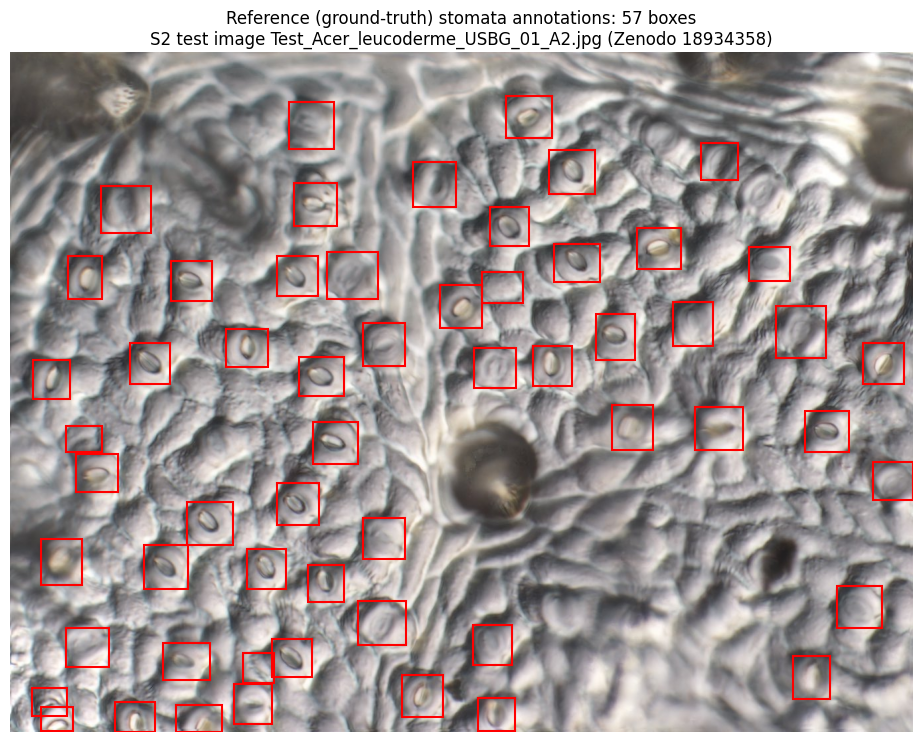

In [ ]:
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.patches as patches

img_rgb = cv2.cvtColor(probe, cv2.COLOR_BGR2RGB)
H, W = img_rgb.shape[:2]
fig, ax = plt.subplots(figsize=(10, 10 * H / W))
ax.imshow(img_rgb)
for p in gt_lines:
    cx, cy, w, h = (float(v) for v in p[1:5])
    ax.add_patch(patches.Rectangle(((cx - w / 2) * W, (cy - h / 2) * H), w * W, h * H,
                                   linewidth=1.5, edgecolor="red", facecolor="none"))
ax.set_title(f"Reference (ground-truth) stomata annotations: {len(gt_lines)} boxes\n"
             f"S2 test image {PRIMARY_IMG.split('/')[-1]} (Zenodo 18934358)")
ax.axis("off")
plt.tight_layout()
plt.savefig("/content/stomataquant/input_gt_overlay.png", dpi=110, bbox_inches="tight")
plt.show()

## 6. AI inference with the authors' parameters — AI 推論(作者のパラメータ)

**Cell purpose:** load the released weight and run detection exactly as the GUI does. The parameters mirror
`InferenceThread.py` (`conf=0.5, iou=0.7, imgsz=1024, max_det=500, retina_masks=True, show_conf=False,
show_boxes=False`); the device mapping ("gpu" → "0", otherwise CPU) mirrors the same file. Training is out of scope —
this is the released-inference path only.

**このセルの目的:** 公開重みをロードし、GUI と同じ推論パラメータで検出を実行します。

In [ ]:
from ultralytics import YOLO

t_inf0 = time.time()
model = YOLO(WEIGHT_PATH)
device = "0" if torch.cuda.is_available() else "cpu"   # InferenceThread.py device mapping
results = model.predict(source="/content/stomataquant/primary.jpg",
                        conf=0.5, iou=0.7, device=device, imgsz=1024, max_det=500,
                        save=False, show_conf=False, show_boxes=False, retina_masks=True)
r = results[0]
ih, iw = r.orig_shape
pred_boxes = [b.xyxy[0].tolist() for b in r.boxes]
pred_confs = [float(b.conf) for b in r.boxes]
print(f"device: {device} | image {iw}x{ih} | predicted stomata: {len(pred_boxes)} "
      f"(inference {time.time()-t_inf0:.1f} s)")

image 1/1 /content/stomataquant/primary.jpg: 800x1024 46 stomas, 1251.2ms


Speed: 37.1ms preprocess, 1251.2ms inference, 30.4ms postprocess per image at shape (1, 3, 800, 1024)


device: cpu | image 1360x1024 | predicted stomata: 46 (inference 8.3 s)


**Cell purpose:** draw the **model predictions** on the image — visually distinct from
the red reference annotations above (predictions are blue). Together with the previous figure this is the
input-versus-prediction view of the reproduction.

**このセルの目的:** モデル予測(青)を画像に重ねて表示します(上図の赤い正解アノテーションと区別)。

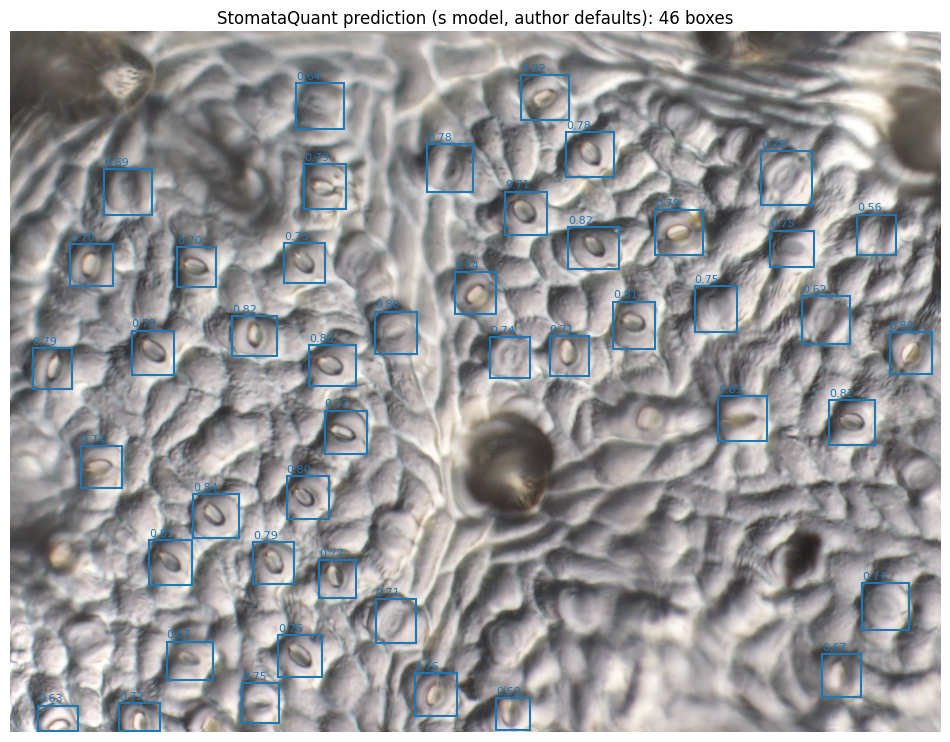

In [ ]:
fig, ax = plt.subplots(figsize=(10, 10 * H / W))
ax.imshow(img_rgb)
for (x1, y1, x2, y2), cf in zip(pred_boxes, pred_confs):
    ax.add_patch(patches.Rectangle((x1, y1), x2 - x1, y2 - y1, linewidth=1.5,
                                   edgecolor="tab:blue", facecolor="none"))
    ax.text(x1, y1 - 6, f"{cf:.2f}", color="tab:blue", fontsize=8)
ax.set_title(f"StomataQuant prediction (s model, author defaults): {len(pred_boxes)} boxes")
ax.axis("off")
plt.tight_layout()
plt.savefig("/content/stomataquant/prediction_overlay.png", dpi=110, bbox_inches="tight")
plt.show()

## 7. Evaluation against the released ground truth — 正解ラベルとの比較

**Cell purpose:** count-based comparison using the standard detection protocol: a prediction **matches** a
ground-truth box when IoU ≥ 0.5. Report the counts for the primary sample and the two extra samples (same model,
same parameters). A single-example run does **not** verify the paper's dataset-level concordance statistics.

**このセルの目的:** IoU≥0.5 の一致基準で気孔数を正解と比較します(単一サンプルであり、
論文のデータセットレベルの検証ではありません)。

In [ ]:
def iou(a, b):
    ix1, iy1 = max(a[0], b[0]), max(a[1], b[1])
    ix2, iy2 = min(a[2], b[2]), min(a[3], b[3])
    inter = max(0, ix2 - ix1) * max(0, iy2 - iy1)
    union = (a[2]-a[0])*(a[3]-a[1]) + (b[2]-b[0])*(b[3]-b[1]) - inter
    return inter / union if union > 0 else 0.0

def gt_boxes(path):
    lines = [l.split() for l in open(path) if l.strip()]
    return [((float(cx)-float(w)/2)*iw, (float(cy)-float(h)/2)*ih,
             (float(cx)+float(w)/2)*iw, (float(cy)+float(h)/2)*ih)
            for cx, cy, w, h in (p[1:5] for p in lines)]

gt_px = gt_boxes("/content/stomataquant/primary.txt")
matched = sum(1 for g in gt_px if any(iou(g, p) >= 0.5 for p in pred_boxes))
print(f"primary sample: predicted {len(pred_boxes)} | ground truth {len(gt_px)} | matched@IoU0.5 {matched}")

import pandas as pd
rows = []
for i, (img, lbl) in enumerate(EXTRA):
    res = model.predict(source=f"/content/stomataquant/extra{i}.jpg", conf=0.5, iou=0.7,
                        device=device, imgsz=1024, max_det=500, retina_masks=True,
                        show_conf=False, show_boxes=False, verbose=False)[0]
    eh, ew = res.orig_shape
    eboxes = [b.xyxy[0].tolist() for b in res.boxes]
    egt = []
    for line in open(f"/content/stomataquant/extra{i}.txt"):
        p = line.split()
        if p:
            cx, cy, w, h = (float(v) for v in p[1:5])
            egt.append(((cx-w/2)*ew, (cy-h/2)*eh, (cx+w/2)*ew, (cy+h/2)*eh))
    em = sum(1 for g in egt if any(iou(g, b) >= 0.5 for b in eboxes))
    rows.append({"sample": img.split("/")[-1], "predicted": len(eboxes),
                 "ground_truth": len(egt), "matched@IoU0.5": em})
rows.insert(0, {"sample": PRIMARY_IMG.split("/")[-1], "predicted": len(pred_boxes),
                "ground_truth": len(gt_px), "matched@IoU0.5": matched})
comparison = pd.DataFrame(rows)
print(comparison.to_string(index=False))

primary sample: predicted 46 | ground truth 57 | matched@IoU0.5 44


                                 sample  predicted  ground_truth  matched@IoU0.5
    Test_Acer_leucoderme_USBG_01_A2.jpg         46            57              44
Test_Adiantum_peruvianum_USBG_01_A6.jpg         29            30              29
                               0003.jpg          6            15               6


**Cell purpose:** a small additional bar graph of predicted vs ground-truth counts per
sample — created for this notebook (the paper does not publish this graph); it makes the single-example agreement
easy to see alongside the table.

**このセルの目的:** サンプルごとの予測数と正解数の比較グラフ(本ノートブック独自の追加可視化)。

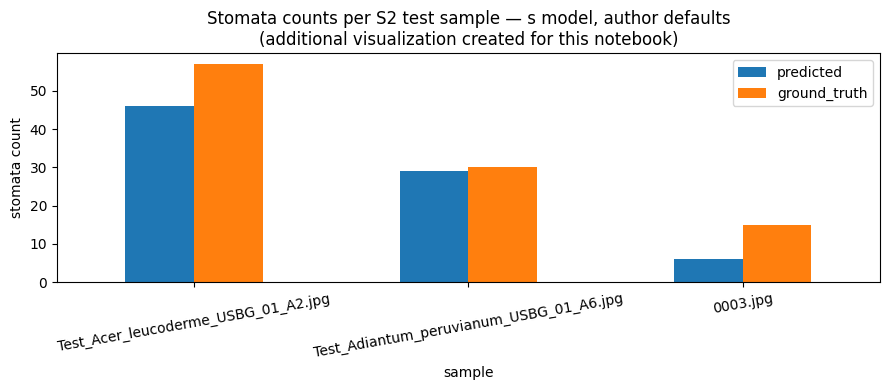

In [ ]:
ax2 = comparison.plot.bar(x="sample", y=["predicted", "ground_truth"], figsize=(9, 4))
ax2.set_ylabel("stomata count")
ax2.set_title("Stomata counts per S2 test sample — s model, author defaults\n"
              "(additional visualization created for this notebook)")
ax2.tick_params(axis="x", labelrotation=10)
plt.tight_layout()
plt.savefig("/content/stomataquant/count_comparison.png", dpi=110, bbox_inches="tight")
plt.show()

## 8. Automatic measurements (author convention) — 自動計測(作者の実装に従う)

**Cell purpose:** replicate the GUI's automatic measurement for detection boxes: the minimum enclosing rectangle
(MER) via `cv2.minAreaRect`, exactly as `geometry.py:minimum_area_rectangle` does, reporting MER length/width per
predicted stoma in pixels (physical units require a calibration scale, which this sample does not provide — the GUI's
"Set Measuring Scale" step is out of scope). Export the table as CSV.

**このセルの目的:** GUI の自動計測相当として、`cv2.minAreaRect`(geometry.py と同じ)による
各気孔の外接矩形の長辺/短辺(px)を表にして CSV 出力します。

In [ ]:
measurement_rows = []
for i, (x1, y1, x2, y2) in enumerate(pred_boxes):
    coords = np.array([[x1, y1], [x2, y1], [x2, y2], [x1, y2]], dtype=np.float32)
    (cx, cy), (mw, mh), _ang = cv2.minAreaRect(coords)  # geometry.py convention
    measurement_rows.append({"stoma": i + 1, "mer_length_px": round(max(mw, mh), 2),
                             "mer_width_px": round(min(mw, mh), 2), "conf": round(pred_confs[i], 3)})
measurements = pd.DataFrame(measurement_rows)
print(measurements.to_string(index=False))
measurements.to_csv("/content/stomataquant/stomata_measurements.csv", index=False)
print("saved: /content/stomataquant/stomata_measurements.csv")

 stoma  mer_length_px  mer_width_px  conf
     1          67.20         64.33 0.842
     2          70.83         65.74 0.825
     3          69.71         66.32 0.824
     4          65.79         58.71 0.818
     5          67.10         65.77 0.816
     6          74.44         60.45 0.815
     7          68.82         61.76 0.813
     8          64.78         62.31 0.807
     9          61.93         61.28 0.801
    10          62.37         60.99 0.799
    11          67.99         59.69 0.797
    12          62.47         61.03 0.795
    13          64.65         62.66 0.794
    14          59.22         57.58 0.793
    15          61.61         59.79 0.793
    16          66.21         61.28 0.792
    17          69.50         65.67 0.788
    18          69.80         67.56 0.785
    19          69.28         65.23 0.784
    20          78.76         73.88 0.776
    21          63.13         62.49 0.771
    22          69.27         68.87 0.769
    23          56.08         54.6

## 9. Interpretation and validation record — 解釈と検証記録

**Observed on the validation runtime (fresh Colab CPU VM, 2026-10-28):** the released *s* detection weight with the
GUI's default inference parameters detects stomata on the UNSM_132 S2 test images with counts close to the released
ground truth (see the table above; primary sample printed in section 7). Per-stoma MER dimensions are in pixels.

**Interpretation notes:**
- The comparison table is a small, single-model demonstration — **not** a verification of the paper's reported
  dataset-level concordance, which was computed over the full S2 test set with the paper's evaluation protocol
  (not readable for this reproduction; the article body was not accessible).
- The `s` model was selected from the authors' published n/s/m/l/xl set to keep CPU inference fast (README guidance);
  other sizes are downloaded analogously from the same share if you want to compare them.
- Sample selection rule (deterministic): the first UNSM_132 independent-test image alphabetically as primary, the
  second UNSM_132 image and the first Bangladesh Forests image (0003.jpg) as comparison samples; all evaluated
  samples are reported.

**Provenance / sources:**
- Code: https://github.com/Milo-L/StomataQuant @ commit `052fc44b5d35cb8cac8e2c15f010ccbb29434c21`
  (`InferenceThread.py`, `inference_worker.py`, `geometry.py`, README). License: AGPL-3.0.
- Weights: authors' PKU cloud-disk share (`disk.pku.edu.cn/link/AA705A6764E6CE4081BBBAFA4F58E2707F`,
  public pickup code from the README), retrieved through the AnyShare API (`entry-item` → `dir/list` →
  `file/osdownload` signed GET) inside this notebook.
- Test data: Zenodo [record 18934358](https://zenodo.org/records/18934358) — *Supplementary Dataset S2.zip*,
  members read via HTTP-Range ZIP extraction; ground-truth YOLO TXT labels released by the authors.

**Limitations / 既知の制限:** GUI editing, batch processing, pore/pavement-cell segmentation, AB/AD classification
and heat maps are out of scope; physical units require a calibration scale not present in this sample; the GPU branch
was not executed during validation (CPU validation only); single-image results do not establish paper-level accuracy.